# EDA: NYC Yellow Taxi, January 2025

**Goal:** understand the raw data well enough to write the silver-layer cleaning rules
and choose the target definition for trip-duration prediction. Every rule in
`libs/quality` cites a finding from this notebook.

Source: NYC TLC trip records, `yellow_tripdata_2025-01.parquet`
(SHA-256 `9af277e4…488a`, versioned with DVC). Reproduce:

```bash
uv sync --all-packages --group eda
make eda   # executes this notebook in place
```

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

RAW = Path("../data/raw/tlc/yellow/yellow_tripdata_2025-01.parquet")
con = duckdb.connect()
con.execute(
    f"""
    create view trips as
    select *,
           date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) / 60.0 as duration_min
    from read_parquet('{RAW.as_posix()}')
    """
)

# One visual system for every chart: one hue for single-series marks, a single-hue
# light->dark ramp for magnitude, recessive grid and axes.
BLUE = "#2a78d6"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK_2,
        "axes.titlecolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "font.size": 10,
    }
)


def q(sql: str):  # noqa: ANN201 - notebook helper
    return con.sql(sql).df()

## 1. Shape and schema

In [2]:
q("describe trips")

,column_name,column_type,null,key,default,extra
0,VendorID,INTEGER,YES,None,None,None
1,tpep_pickup_datetime,TIMESTAMP,YES,None,None,None
2,tpep_dropoff_datetime,TIMESTAMP,YES,None,None,None
3,passenger_count,BIGINT,YES,None,None,None
4,trip_distance,DOUBLE,YES,None,None,None
5,RatecodeID,BIGINT,YES,None,None,None
6,store_and_fwd_flag,VARCHAR,YES,None,None,None
7,PULocationID,INTEGER,YES,None,None,None
8,DOLocationID,INTEGER,YES,None,None,None
9,payment_type,BIGINT,YES,None,None,None


In [3]:
q(
    """
    select count(*) as rows,
           min(tpep_pickup_datetime) as first_pickup,
           max(tpep_pickup_datetime) as last_pickup
    from trips
    """
)

,rows,first_pickup,last_pickup
0,3475226,2024-12-31 20:47:55,2025-02-01 00:00:44


3.48M trips, 20 source columns. Pickups spill outside January on both sides, so the
month boundary must be enforced explicitly.

## 2. Data-quality issues

In [4]:
q(
    """
    select
      count(*) filter (where tpep_pickup_datetime < '2025-01-01'
                         or tpep_pickup_datetime >= '2025-02-01')            as pickup_outside_month,
      count(*) filter (where duration_min <= 0)                              as non_positive_duration,
      count(*) filter (where duration_min < 1)                               as duration_under_1_min,
      count(*) filter (where duration_min > 120)                             as duration_over_2_h,
      count(*) filter (where duration_min > 24 * 60)                         as duration_over_1_day,
      count(*) filter (where trip_distance <= 0)                             as zero_distance,
      count(*) filter (where trip_distance > 100)                            as distance_over_100_mi,
      count(*) filter (where PULocationID in (264, 265)
                          or DOLocationID in (264, 265))                     as unknown_zone,
      count(*) filter (where total_amount < 0)                               as negative_total
    from trips
    """
).T.rename(columns={0: "rows"})

,rows
pickup_outside_month,22
non_positive_duration,2051
duration_under_1_min,40111
duration_over_2_h,2014
duration_over_1_day,20
zero_distance,90893
distance_over_100_mi,162
unknown_zone,28357
negative_total,63037


### 2a. Charge + reversal pairs (hidden duplicates)

Negative totals are not just refunds: most are a **reversal row** that exactly mirrors
a charged trip (same vendor, timestamps, zones and distance). Keeping both would put the
same trip twice in the data, possibly once in train and once in validation, which
inflates validation scores.

In [5]:
q(
    """
    with k as (
      select VendorID, tpep_pickup_datetime, tpep_dropoff_datetime,
             PULocationID, DOLocationID, trip_distance,
             count(*) as n,
             count(*) filter (where total_amount < 0) as neg,
             count(*) filter (where total_amount > 0) as pos
      from trips group by all
    )
    select count(*) filter (where n > 1)              as duplicated_trip_keys,
           count(*) filter (where neg > 0 and pos > 0) as charge_reversal_pairs,
           count(*) filter (where neg > 0 and pos = 0) as negative_only_rows
    from k
    """
)

,duplicated_trip_keys,charge_reversal_pairs,negative_only_rows
0,52531,52531,10506


### 2b. The "metadata-missing" cohort

About 15.5% of rows have NULL `passenger_count`, `RatecodeID` and `store_and_fwd_flag`
with `payment_type = 0`. Their duration and distance distributions are plausible
(only the extreme tail is broken), so they are **kept** and flagged rather than dropped.
None of the dropped columns is a model feature.

In [6]:
q(
    """
    select passenger_count is null as metadata_missing,
           count(*) as rows,
           round(median(trip_distance), 2) as median_distance_mi,
           round(median(duration_min), 1) as median_duration_min,
           round(quantile_cont(trip_distance, 0.999), 1) as p999_distance_mi,
           max(trip_distance) as max_distance_mi
    from trips group by 1 order by 1
    """
)

,metadata_missing,rows,median_distance_mi,median_duration_min,p999_distance_mi,max_distance_mi
0,False,2935077,1.60,11.3,29.4,44730.30
1,True,540149,2.04,13.8,22.0,276423.57


## 3. Target: trip duration

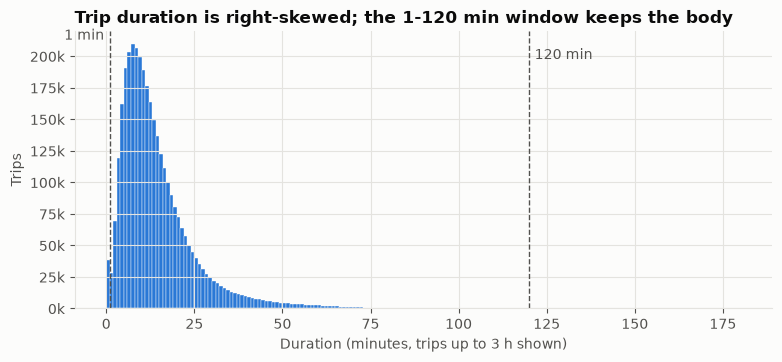

In [7]:
dur = q(
    """
    select duration_min from trips
    where duration_min > 0 and duration_min <= 180
    """
)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(dur["duration_min"], bins=180, color=BLUE, edgecolor=SURFACE, linewidth=0.3)
for x, label, y_frac in [(1, "1 min", 0.97), (120, "120 min", 0.9)]:
    ax.axvline(x, color=INK_2, linewidth=1, linestyle="--")
    ax.annotate(label, (x, ax.get_ylim()[1] * y_frac), xytext=(-4 if x == 1 else 4, 0),
                textcoords="offset points", ha="right" if x == 1 else "left", color=INK_2)
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_title("Trip duration is right-skewed; the 1-120 min window keeps the body")
ax.set_xlabel("Duration (minutes, trips up to 3 h shown)")
ax.set_ylabel("Trips")
plt.show()

In [8]:
q(
    """
    select quantile_cont(duration_min, [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999])
           as duration_quantiles_min
    from trips
    """
)

,duration_quantiles_min
0,"[0.666667, 3.366667, 7.283333, 11.7, 18.333333..."


**Target window: 1 to 120 minutes.** Under 1 minute is almost always a meter test or
cancelled trip. The common course cut-off of 60 minutes would also drop legitimate long
trips (airport runs in traffic), so 120 minutes is used; above it the tail is dominated
by meters left running (20 trips exceed a full day).

## 4. Distance vs duration

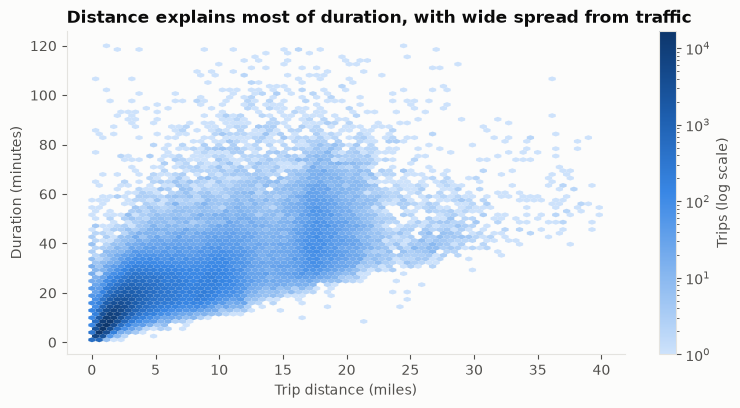

In [9]:
dd = q(
    """
    select trip_distance, duration_min from trips
    where duration_min between 1 and 120 and trip_distance > 0 and trip_distance <= 40
    using sample 300000 rows (reservoir, 42)
    """
)
fig, ax = plt.subplots(figsize=(9, 4.2))
hb = ax.hexbin(dd["trip_distance"], dd["duration_min"], gridsize=70, cmap=BLUES, bins="log",
               mincnt=1, linewidths=0)
fig.colorbar(hb, ax=ax, label="Trips (log scale)")
ax.set_title("Distance explains most of duration, with wide spread from traffic")
ax.set_xlabel("Trip distance (miles)")
ax.set_ylabel("Duration (minutes)")
ax.grid(False)
plt.show()

In [10]:
q(
    """
    select round(corr(duration_min, trip_distance), 3) as pearson_r,
           count(*) filter (where trip_distance / (duration_min / 60) > 80) as implied_speed_over_80_mph
    from trips
    where duration_min between 1 and 120 and trip_distance > 0 and trip_distance <= 100
    """
)

,pearson_r,implied_speed_over_80_mph
0,0.802,186


Distance correlates strongly with duration (r ≈ 0.80) but leaves a lot unexplained:
that is the job of time-of-day and zone features. A handful of trips imply speeds above
80 mph, which is physically implausible in NYC: a speed rule removes them.

## 5. Time-of-day and day-of-week

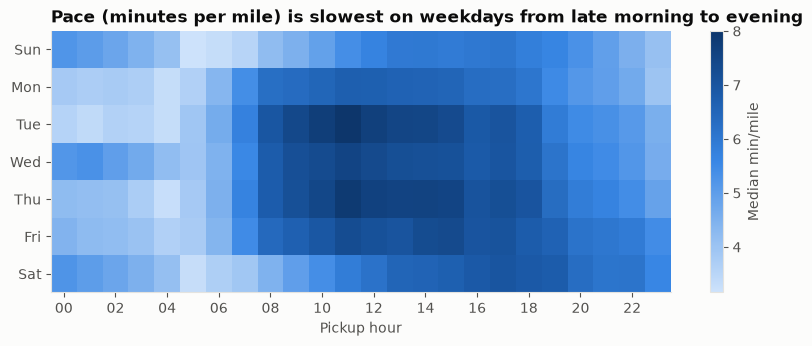

In [11]:
hw = q(
    """
    select dayofweek(tpep_pickup_datetime) as dow, hour(tpep_pickup_datetime) as hour,
           median(duration_min / nullif(trip_distance, 0)) as min_per_mile
    from trips
    where duration_min between 1 and 120 and trip_distance between 0.5 and 100
      and tpep_pickup_datetime >= '2025-01-01' and tpep_pickup_datetime < '2025-02-01'
    group by all
    """
)
grid = hw.pivot(index="dow", columns="hour", values="min_per_mile").sort_index()
fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(grid.values, aspect="auto", cmap=BLUES)
ax.set_yticks(range(7), ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"])
ax.set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
ax.set_xlabel("Pickup hour")
ax.set_title("Pace (minutes per mile) is slowest on weekdays from late morning to evening")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Median min/mile")
plt.show()

Congestion is clearly time-dependent: weekdays from about 10:00 to 18:00 are the slowest
(peaking Tuesday-Thursday around midday); nights, early mornings and weekend mornings are
the fastest. **Pickup hour and day of week are strong features**,
and they are known at pickup time, so they do not leak the target.

## 6. Zones

In [12]:
q(
    """
    select count(distinct PULocationID) as pickup_zones_used,
           count(distinct DOLocationID) as dropoff_zones_used,
           count(distinct (PULocationID, DOLocationID)) as zone_pairs_used
    from trips
    """
)

,pickup_zones_used,dropoff_zones_used,zone_pairs_used
0,261,260,32797


261 pickup zones and tens of thousands of zone pairs: high-cardinality categoricals.
Zone IDs 264/265 mean "unknown"/"outside NYC" and carry no location signal.

## 7. Cleaning funnel (what silver keeps)

In [13]:
funnel = q(
    """
    with base as (
      select *,
             row_number() over (
               partition by VendorID, tpep_pickup_datetime, tpep_dropoff_datetime,
                            PULocationID, DOLocationID, trip_distance
               order by total_amount desc) as rn
      from trips
    ),
    steps as (
      select
        count(*) as raw,
        count(*) filter (where total_amount >= 0) as drop_reversals_and_voids,
        count(*) filter (where total_amount >= 0 and rn = 1) as drop_duplicates,
        count(*) filter (where total_amount >= 0 and rn = 1
          and tpep_pickup_datetime >= '2025-01-01' and tpep_pickup_datetime < '2025-02-01')
          as pickup_in_month,
        count(*) filter (where total_amount >= 0 and rn = 1
          and tpep_pickup_datetime >= '2025-01-01' and tpep_pickup_datetime < '2025-02-01'
          and duration_min between 1 and 120) as duration_1_to_120,
        count(*) filter (where total_amount >= 0 and rn = 1
          and tpep_pickup_datetime >= '2025-01-01' and tpep_pickup_datetime < '2025-02-01'
          and duration_min between 1 and 120
          and trip_distance > 0 and trip_distance <= 100) as distance_valid,
        count(*) filter (where total_amount >= 0 and rn = 1
          and tpep_pickup_datetime >= '2025-01-01' and tpep_pickup_datetime < '2025-02-01'
          and duration_min between 1 and 120
          and trip_distance > 0 and trip_distance <= 100
          and trip_distance / (duration_min / 60) <= 80) as speed_plausible,
        count(*) filter (where total_amount >= 0 and rn = 1
          and tpep_pickup_datetime >= '2025-01-01' and tpep_pickup_datetime < '2025-02-01'
          and duration_min between 1 and 120
          and trip_distance > 0 and trip_distance <= 100
          and trip_distance / (duration_min / 60) <= 80
          and PULocationID not in (264, 265) and DOLocationID not in (264, 265))
          as known_zones
      from base
    )
    unpivot steps on columns(*) into name step value rows
    """
)
funnel["share_of_raw_%"] = (100 * funnel["rows"] / funnel["rows"].iloc[0]).round(2)
funnel

,step,rows,share_of_raw_%
0,raw,3475226,100.00
1,drop_reversals_and_voids,3412189,98.19
2,drop_duplicates,3412187,98.19
3,pickup_in_month,3412165,98.19
4,duration_1_to_120,3376748,97.17
5,distance_valid,3312829,95.33
6,speed_plausible,3312645,95.32
7,known_zones,3287442,94.60


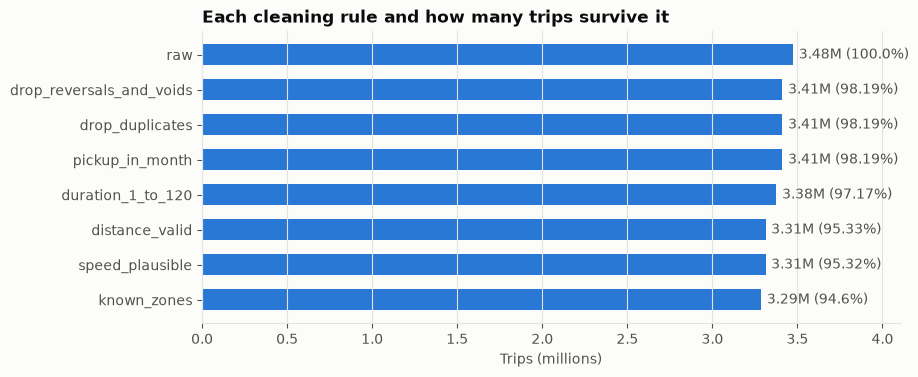

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(funnel["step"][::-1], funnel["rows"][::-1] / 1e6, color=BLUE, height=0.6)
for y, (v, s) in enumerate(zip(funnel["rows"][::-1], funnel["share_of_raw_%"][::-1], strict=True)):
    ax.annotate(f"{v / 1e6:.2f}M ({s}%)", (v / 1e6, y), xytext=(4, 0), textcoords="offset points",
                va="center", color=INK_2)
ax.set_xlim(0, funnel["rows"].max() / 1e6 * 1.18)
ax.set_title("Each cleaning rule and how many trips survive it")
ax.set_xlabel("Trips (millions)")
ax.grid(axis="y", visible=False)
plt.show()

## 8. Decisions carried into the pipeline

| # | Rule (silver) | Evidence |
|---|---|---|
| R1 | Drop rows with `total_amount < 0` (reversals and voids) | §2a: 52.5k charge/reversal pairs + 10.5k negative-only rows |
| R2 | One row per trip key (vendor, pickup, dropoff, zones, distance) | §2a |
| R3 | Pickup inside the file's month | §1: pickups outside January |
| R4 | Duration 1-120 minutes | §3 |
| R5 | Distance > 0 and ≤ 100 miles | §2, §2b: zero distances and a 276k-mile maximum |
| R6 | Implied speed ≤ 80 mph | §4 |
| R7 | Pickup and dropoff zone not 264/265 (gold only: no location signal) | §6 |
| F1 | Keep the metadata-missing cohort, add an `is_metadata_missing` flag | §2b |

**Features known at pickup:** pickup/dropoff zone, trip distance, pickup hour,
day of week. **Target:** duration in minutes.